<a href="https://colab.research.google.com/github/Nakib-Nasrullah/Research-Skill/blob/main/Boosting_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install boosting libraries
!pip install xgboost lightgbm catboost -q

print("✅ All libraries installed successfully!")

✅ All libraries installed successfully!


In [3]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


2. Introduction to Boosting

What is Gradient Boosting?

Gradient boosting builds models sequentially, where each new model corrects errors made by previous models.

Three Popular Implementations:

| Model | Best For | Speed | Accuracy |
| --- | --- | --- | --- |
| **XGBoost** | General purpose | Medium | High |
| **LightGBM** | Large datasets | Fast ⚡ | High |
| **CatBoost** | Categorical features | Slower | Highest |

When to Use Boosting:

* ✅ Need highest accuracy
* ✅ Need highest accuracy


* ✅ Structured/tabular data


* ✅ Kaggle competitions


* ✅ Complex patterns in data



3. Dataset: Iris Flowers



**Source:** Kaggle Dataset (built into sklearn)

**Link:** [https://www.kaggle.com/datasets/uciml/iris](https://www.kaggle.com/datasets/uciml/iris)

**Description:** Classic dataset for flower species classification

**Features:**

* Sepal Length


* Sepal Width


* Petal Length


* Petal Width



**Target:** 3 flower species (Setosa, Versicolor, Virginica)

In [4]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Load the training dataset from Google Drive
iris = pd.read_csv('/content/drive/MyDrive/Datasets/Iris.csv')

In [7]:
# Drop the 'Id' column and 'Species' for features
X = iris.drop(['Id', 'Species'], axis=1)

# Use 'Species' as the target
y = iris['Species']

# Map species names to integers for the models
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

print("✅ Dataset loaded successfully!")
print(f"\nDataset Shape: {X.shape}")
print(f"\nTarget Classes: {le.classes_}")

✅ Dataset loaded successfully!

Dataset Shape: (150, 4)

Target Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


# **4.Data Exploration**

In [8]:
#Display first few rows
print("First 5 rows")
X.head()

First 5 rows


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [9]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20
)

print("✅ Data split complete!")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

✅ Data split complete!
Training samples: 120
Testing samples: 30


# **5. Model 1: XGBoost**



**XGBoost** (Extreme Gradient Boosting)

* Most popular gradient boosting library


* Great balance of speed and accuracy


* Excellent documentation and community support

In [10]:
print("🔵 Training XGBoost Model...")

# Initialize XGBoost model
xgb_model = xgb.XGBClassifier(
    n_estimators=50,       # Number of trees
    learning_rate=0.1,     # Step size
    max_depth=5,           # Tree depth
    random_state=20
)
# Train the model[cite: 10]
xgb_model.fit(X_train, y_train)

# Make predictions
xgb_pred = xgb_model.predict(X_test)

# Calculate accuracy
xgb_acc = accuracy_score(y_test, xgb_pred)

print(f"✅ XGBoost Training Complete!")
print(f"✅ Accuracy: {xgb_acc:.4f} ({xgb_acc*100:.2f}%)")

🔵 Training XGBoost Model...
✅ XGBoost Training Complete!
✅ Accuracy: 0.9000 (90.00%)


# **6. Model 2: LightGBM**



**LightGBM** (Light Gradient Boosting Machine)

* Fastest training speed


* Low memory usage


* Best for large datasets (>10,000 rows)

In [11]:
print("Training LightGBM Model...")

# Initialize LightGBM model
lgb_model = lgb.LGBMClassifier(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    verbose=-1,            # Suppress output
    force_col_wise=True    # Remove warnings
)

# Train the model
lgb_model.fit(X_train, y_train)

# Make predictions
lgb_pred = lgb_model.predict(X_test)

# Calculate accuracy
lgb_acc = accuracy_score(y_test, lgb_pred)

print(f"✅ LightGBM Training Complete!")
print(f"✅ Accuracy: {lgb_acc:.4f} ({lgb_acc*100:.2f}%)")

Training LightGBM Model...
✅ LightGBM Training Complete!
✅ Accuracy: 0.9000 (90.00%)


# **7. Model 3: CatBoost**



**CatBoost** (Categorical Boosting)

* Handles categorical features automatically


* Often achieves highest accuracy


* No need for feature encoding

In [12]:
print("🟢 Training CatBoost Model...")

# Initialize CatBoost model
cat_model = CatBoostClassifier(
    iterations=50,         # Number of trees
    learning_rate=0.1,
    depth=5,               # Tree depth
    random_state=42,
    verbose=0              # Suppress output
)

# Train the model
cat_model.fit(X_train, y_train)

# Make predictions
cat_pred = cat_model.predict(X_test)

# Calculate accuracy
cat_acc = accuracy_score(y_test, cat_pred)

print(f"✅ CatBoost Training Complete!")
print(f"✅ Accuracy: {cat_acc:.4f} ({cat_acc*100:.2f}%)")

🟢 Training CatBoost Model...
✅ CatBoost Training Complete!
✅ Accuracy: 0.9333 (93.33%)


In [13]:
# Detailed classification report for each model
print("\n📝 Detailed Classification Reports:\n")

print("XGBoost:")
print(classification_report(y_test, xgb_pred, target_names=le.classes_))

print("\nLightGBM:")
print(classification_report(y_test, lgb_pred, target_names=le.classes_))

print("\nCatBoost:")
print(classification_report(y_test, cat_pred, target_names=le.classes_))


📝 Detailed Classification Reports:

XGBoost:
                 precision    recall  f1-score   support

    Iris-setosa       0.89      1.00      0.94         8
Iris-versicolor       0.83      0.91      0.87        11
 Iris-virginica       1.00      0.82      0.90        11

       accuracy                           0.90        30
      macro avg       0.91      0.91      0.90        30
   weighted avg       0.91      0.90      0.90        30


LightGBM:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         8
Iris-versicolor       0.79      1.00      0.88        11
 Iris-virginica       1.00      0.73      0.84        11

       accuracy                           0.90        30
      macro avg       0.93      0.91      0.91        30
   weighted avg       0.92      0.90      0.90        30


CatBoost:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00         8
Iris-versicol

Visualizations
# **bold text**
Visual comparison of model performance.

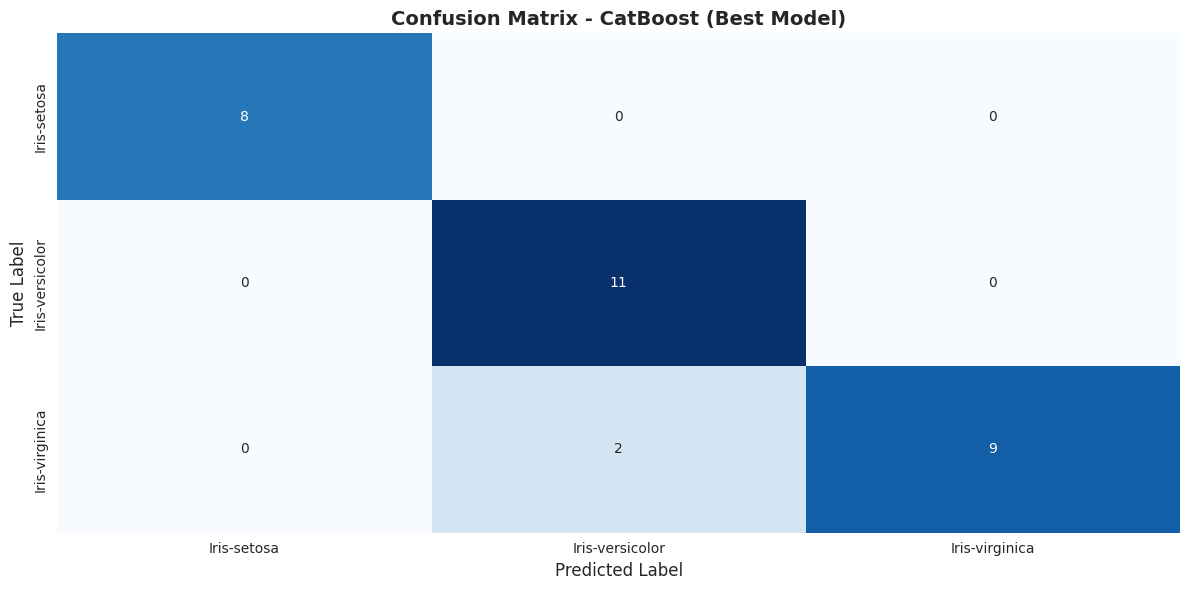

 Confusion matrix for the best model (CatBoost) plotted successfully!


In [16]:
# Determine the best model dynamically based on accuracy
accuracies = {
    'XGBoost': xgb_acc,
    'LightGBM': lgb_acc,
    'CatBoost': cat_acc
}
best_model = max(accuracies, key=accuracies.get)

# Select predictions for the best model
if best_model == 'XGBoost':
    best_pred = xgb_pred
elif best_model == 'LightGBM':
    best_pred = lgb_pred
else:
    best_pred = cat_pred.ravel()  # Flatten if necessary

# Compute confusion matrix
cm = confusion_matrix(y_test, best_pred)

# Plot Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)

plt.title(f'Confusion Matrix - {best_model} (Best Model)', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

print(f" Confusion matrix for the best model ({best_model}) plotted successfully!")

# **10. Key Takeaways**


What We Learned:

1. **XGBoost**


* ✅ Most popular gradient boosting library


* ✅ Great balance of speed and accuracy


* ✅ Excellent for general purpose use




2. **LightGBM**


* ✅ Fastest training speed


* ✅ Low memory usage


* ✅ Best for large datasets




3. **CatBoost**


* ✅ Handles categorical features automatically


* ✅ Often achieves highest accuracy


* ✅ Robust to hyperparameters


# **When to Use Each:**

* **Use XGBoost:** General purpose, balanced needs


* **Use LightGBM:** Large datasets (>10K rows), need speed


* **Use CatBoost:** Many categorical features, need highest accuracy



Important Concepts:

* **n_estimators:** Number of trees (more = better but slower)


* **learning_rate:** Step size (lower = more accurate but needs more trees)


* **max_depth:** Tree complexity (higher = more complex patterns but may overfit)



---

11. Homework Assignment



📝 **Task:** Titanic Survival Prediction

**Dataset:** Titanic - Machine Learning from Disaster

**Kaggle Link:** [https://www.kaggle.com/c/titanic/data](https://www.kaggle.com/c/titanic/data)